## Neural Network
[Artificial neural networks (ANNs)](https://en.wikipedia.org/wiki/Artificial_neural_network), usually simply called neural networks (NNs) or neural nets, are computing systems inspired by the biological neural networks that constitute animal brains.
<p>
An ANN is based on a collection of connected units or nodes called artificial neurons, which loosely model the neurons in a biological brain. Each connection, like the synapses in a biological brain, can transmit a signal to other neurons. An artificial neuron receives signals then processes them and can signal neurons connected to it. The "signal" at a connection is a real number, and the output of each neuron is computed by some non-linear function of the sum of its inputs. The connections are called edges. Neurons and edges typically have a weight that adjusts as learning proceeds. The weight increases or decreases the strength of the signal at a connection. Neurons may have a threshold such that a signal is sent only if the aggregate signal crosses that threshold.
<p>
Typically, neurons are aggregated into layers. Different layers may perform different transformations on their inputs. Signals travel from the first layer (the input layer), to the last layer (the output layer), possibly after traversing the layers multiple times.
<p>
Met een neuraal net kun je dus ook voorspellingen maken, net als met regressie of Naive Bayes Classification of Decision Trees.




# Voorbeeld 1: scikit-learn
We gaan eerst scikit-learn gebruiken: https://scikit-learn.org/stable/

Om deze methode te kunnen toepassen, lezen we eerst de benodigde libraries in:

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm

from sklearn.model_selection import train_test_split

from sklearn import metrics
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import mean_squared_error, mean_absolute_error
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler

We hebben data nodig: https://archive.ics.uci.edu/dataset/477/real+estate+valuation+data+set

In [29]:
# =====================Inladen bestanden=======================================
# Tabellen met parameters ophalen uit dit bestand.
RealEstate = pd.read_excel("Real_estate_valuation_data_set.xlsx")
# =============================================================================
RealEstate.head()

,No,X1 transaction date,X2 house age,X3 distance to the nearest MRT station,X4 number of convenience stores,X5 latitude,X6 longitude,Y house price of unit area
0,1,2012.916667,32.0,84.87882,10,24.98298,121.54024,37.9
1,2,2012.916667,19.5,306.59470,9,24.98034,121.53951,42.2
2,3,2013.583333,13.3,561.98450,5,24.98746,121.54391,47.3
3,4,2013.500000,13.3,561.98450,5,24.98746,121.54391,54.8
4,5,2012.833333,5.0,390.56840,5,24.97937,121.54245,43.1


## Neuraal netwerk voor regressie
Laten we eens kijken of we een voorspelling kunnen maken. In dit voorbeeld gaan we kijken of we de huisprijs kunnen voorspellen op basis van X1 tot en met X6.
<p>
Dat doen we door eerst de data te verdelen in een trainings-set en een test-set.
<p>
Met de trainings-set 'train' je het model.
<p>
Met de test-set voorspel je vervolgens.   

In [30]:
X = RealEstate.iloc[:,2:-1]
Y = RealEstate.iloc[:,-1:]
Y = np.ravel(Y)

In [31]:
X.head()

,X2 house age,X3 distance to the nearest MRT station,X4 number of convenience stores,X5 latitude,X6 longitude
0,32.0,84.87882,10,24.98298,121.54024
1,19.5,306.59470,9,24.98034,121.53951
2,13.3,561.98450,5,24.98746,121.54391
3,13.3,561.98450,5,24.98746,121.54391
4,5.0,390.56840,5,24.97937,121.54245


In [32]:
Y

array([ 37.9,  42.2,  47.3,  54.8,  43.1,  32.1,  40.3,  46.7,  18.8,
        22.1,  41.4,  58.1,  39.3,  23.8,  34.3,  50.5,  70.1,  37.4,
        42.3,  47.7,  29.3,  51.6,  24.6,  47.9,  38.8,  27. ,  56.2,
        33.6,  47. ,  57.1,  22.1,  25. ,  34.2,  49.3,  55.1,  27.3,
        22.9,  25.3,  47.7,  46.2,  15.9,  18.2,  34.7,  34.1,  53.9,
        38.3,  42. ,  61.5,  13.4,  13.2,  44.2,  20.7,  27. ,  38.9,
        51.7,  13.7,  41.9,  53.5,  22.6,  42.4,  21.3,  63.2,  27.7,
        55. ,  25.3,  44.3,  50.7,  56.8,  36.2,  42. ,  59. ,  40.8,
        36.3,  20. ,  54.4,  29.5,  36.8,  25.6,  29.8,  26.5,  40.3,
        36.8,  48.1,  17.7,  43.7,  50.8,  27. ,  18.3,  48. ,  25.3,
        45.4,  43.2,  21.8,  16.1,  41. ,  51.8,  59.5,  34.6,  51. ,
        62.2,  38.2,  32.9,  54.4,  45.7,  30.5,  71. ,  47.1,  26.6,
        34.1,  28.4,  51.6,  39.4,  23.1,   7.6,  53.3,  46.4,  12.2,
        13. ,  30.6,  59.6,  31.3,  48. ,  32.5,  45.5,  57.4,  48.6,
        62.9,  55. ,

In [33]:
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, random_state =1)

Vervolgens trainen we het model:

In [34]:
model = MLPRegressor(hidden_layer_sizes = (100, 100),
                     activation = "relu",
                     max_iter = 300)

model.fit(X_train, Y_train)
Y_pred = model.predict(X_test)

We gebruiken als neuraal netwerkmodel de [MLP Regressor](https://scikit-learn.org/stable/modules/generated/sklearn.neural_network.MLPRegressor.html):<br>

tutorial in de vorm van een [video](https://www.youtube.com/watch?v=_JG71FIP1rk).

Is dit neurale netwerk nu een goede voorspeller?

In [35]:
print("MSE:", mean_squared_error(Y_test,Y_pred))
print("MAE:", mean_absolute_error(Y_test,Y_pred))

MSE: 52.92259530587202
MAE: 5.208840906742416


In [36]:
df = pd.DataFrame()

df['werkelijke_huisprijs'] = Y_test
df['voorspelde_huisprijs'] = Y_pred
df

,werkelijke_huisprijs,voorspelde_huisprijs
0,27.3,27.500335
1,54.4,51.969514
2,22.0,23.064283
3,11.6,19.735294
4,45.4,51.634133
...,...,...
99,55.2,51.029025
100,46.6,22.447330
101,46.2,48.052372
102,24.4,26.498735


In [37]:
weight = df[['werkelijke_huisprijs', 'voorspelde_huisprijs']].pct_change(axis = 'columns', periods = 1 ).abs()
total = sum(weight['voorspelde_huisprijs'])

average_miscalc = (total / len(weight)) * 100
print(f"De afwijking tussen voorspelde en daadwerkelijke huisprijs is gemiddeld {round(average_miscalc, 2)} % \n\n\n" )

De afwijking tussen voorspelde en daadwerkelijke huisprijs is gemiddeld 17.05 % 





We kunnnen een neuraal netwerk dus gebruiken bij het voorspellen van een continue variabele.

## Scatterplot
In onderstaand scatterplot wordt het voorspelde gewicht en het werkelijke gewicht tegen elkaar uitgezet:

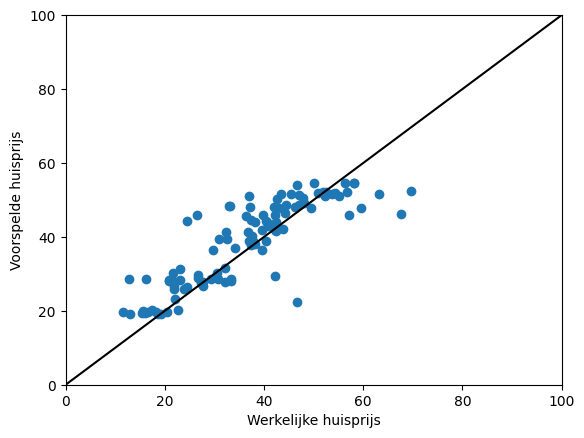

In [39]:
plt.scatter(Y_test, Y_pred)
plt.xlim(0, 100)
plt.ylim(0, 100)
plt.ylabel('Voorspelde huisprijs')
plt.xlabel('Werkelijke huisprijs')
plt.plot([0, 100], [0,100], 'black') #1 to 1 line
plt.show()

Het model van het neural network heeft voorspellingen gemaakt en deze staan uitgezet tegen de daadwerkelijke huisprijzen. In het ideale geval liggen alle punten op de ideaallijn en hoe dichter deze bij de lijn liggen, hoe beter de voorspellingen zijn. Hieruit blijkt dat het neural network een redelijk goed model is voor het bepalen van een continue variabele.

# Voorbeeld 2: Keras
Zelfde model, nu met Keras: https://keras.io/

In [40]:
import keras
from keras.models import Sequential
from keras.layers import Dense, Activation

## Neuraal netwerk voor regressie
We trainen en testen het model:

In [41]:
model = Sequential()
model.add(Dense(100, input_dim = X_train.shape[1], activation="relu"))
model.add(Dense(100, activation="relu"))
model.add(Dense(1))
model.compile(loss="mse", optimizer=keras.optimizers.Adam(learning_rate=0.001), metrics=["mae"])

history=model.fit(X_train, Y_train, epochs=300)

Epoch 1/300
10/10 [==============================] - 1s 3ms/step - loss: 2816.5291 - mae: 39.1678
Epoch 2/300
10/10 [==============================] - 0s 3ms/step - loss: 635.2554 - mae: 17.0887
Epoch 3/300
10/10 [==============================] - 0s 2ms/step - loss: 235.8786 - mae: 10.9792
Epoch 4/300
10/10 [==============================] - 0s 3ms/step - loss: 177.0147 - mae: 9.8109
Epoch 5/300
10/10 [==============================] - 0s 3ms/step - loss: 136.0168 - mae: 8.2808
Epoch 6/300
10/10 [==============================] - 0s 3ms/step - loss: 92.7606 - mae: 6.5435
Epoch 7/300
10/10 [==============================] - 0s 3ms/step - loss: 82.7901 - mae: 6.2624
Epoch 8/300
10/10 [==============================] - 0s 3ms/step - loss: 81.6320 - mae: 6.0785
Epoch 9/300
10/10 [==============================] - 0s 3ms/step - loss: 80.8033 - mae: 6.0545
Epoch 10/300
10/10 [==============================] - 0s 3ms/step - loss: 80.7011 - mae: 6.0169
Epoch 11/300
10/10 [====================

Is dit neuraal net nu een goede voorspeller?

In [42]:
model.evaluate(X_test,Y_test)

4/4 [==============================] - 0s 4ms/step - loss: 75.1451 - mae: 6.8688


[75.14509582519531, 6.868792533874512]

Vergeleken met de voorgaande uitkomsten (met het sckit-learn model) zijn hier de MSE en de MAE hoger.

## Loss-plot


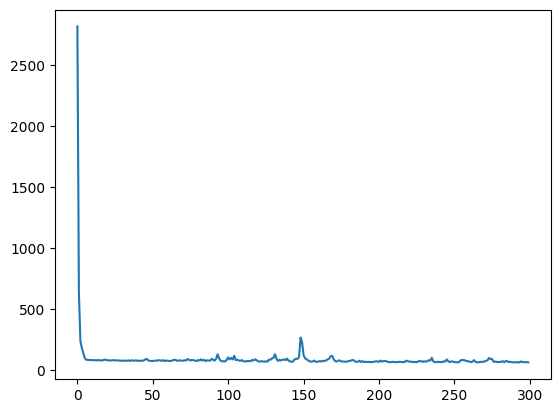

In [50]:
plt.plot(history.history["loss"])

Slechts na enkele iteraties bereikt de loss-functie al een minimum, oftewel: het model wordt niet beter van meerdere trainingssessies.<br>
Bij 150 is er een kleine piek, daarna blijft het 'verlies' (= afwijking tov de werkelijkheid) gelijk.

In [51]:
keras.backend.clear_session()

#Nadeel van een neuraal netwerk
Probeer de uitkomst van bovenstaande regressie-analyses met behulp van een neuraal netwerk maar eens uit te leggen aan een leek:<br>
- Hoe ziet het voorspelmodel er nu uit?<br>
- Wat gebeurt er precies in / tussen de 2 hidden layers met 100 neuronen?<br>

<p>

Bij de andere voorspelmodellen (lineaire regressie, naive Bayes en beslisbomen) is nog enigszins te volgen wat het model doet. Het neurale netwerk is een fijn voorbeeld van een black box:<br>
alleen wat er in gaat (data) en wat er uitkomt (voorspelling) is bekend.<br>
<p>
https://en.wikipedia.org/wiki/Black_box

